In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [5]:
train_df = pd.read_csv("trainR.csv")
test_df = pd.read_csv("testR.csv")
store_df = pd.read_csv("storeR.csv")

print("TRAIN DATA:", train_df.shape)
print("TEST DATA:", test_df.shape)
print("STORE DATA:", store_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nStore columns:")
print(store_df.columns.tolist())

display(train_df.head())
display(test_df.head())
display(store_df.head())

C:\Users\ADS2609024\AppData\Local\Temp\17\ipykernel_1368\1679908929.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv("trainR.csv")


TRAIN DATA: (1017209, 9)
TEST DATA: (41088, 8)
STORE DATA: (1115, 10)

Training columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Test columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Store columns:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


Sales column information
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Missing values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Open status:
Open
1    844392
0    172817
Name: count, dtype: int64

Sales distribution:


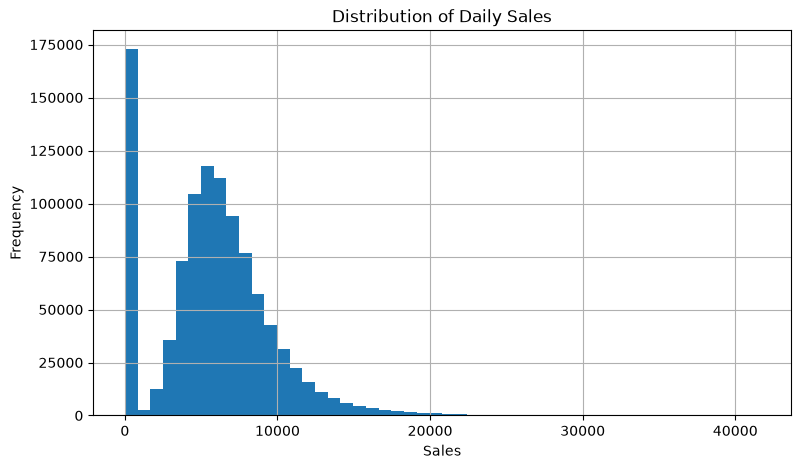

In [6]:
print("Sales column information")
print(train_df["Sales"].describe())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nOpen status:")
print(train_df["Open"].value_counts(dropna=False))

print("\nSales distribution:")
train_df["Sales"].hist(bins=50, figsize=(9, 5))
plt.title("Distribution of Daily Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [7]:
df = train_df.merge(
    store_df,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", df.shape)
display(df.head())

Merged dataset shape: (1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [8]:
df["Date"] = pd.to_datetime(df["Date"])

# Keep records when the store is open
df = df[df["Open"] == 1].copy()

# Remove rows where sales are zero or negative
df = df[df["Sales"] > 0].copy()

# Create useful date features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print("Cleaned dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Missing values:\n", df.isnull().sum().sort_values(ascending=False).head(10))

Cleaned dataset shape: (844338, 22)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Missing values:
 PromoInterval                423292
Promo2SinceYear              423292
Promo2SinceWeek              423292
CompetitionOpenSinceMonth    268600
CompetitionOpenSinceYear     268600
CompetitionDistance            2186
Open                              0
Customers                         0
Sales                             0
Date                              0
dtype: int64


In [9]:
features = [
    "Store",
    "DayOfWeek",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "StoreType",
    "Assortment",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "PromoInterval",
    "Year",
    "Month",
    "Day",
    "WeekOfYear"
]

target = "Sales"

model_df = df[features + [target, "Date"]].copy()

# Fill numerical missing values using each column's median
numeric_columns = model_df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    model_df[column] = model_df[column].fillna(
        model_df[column].median()
    )

# Fill missing categorical values
categorical_columns = model_df.select_dtypes(
    include=["object", "str", "category"]
).columns

for column in categorical_columns:
    model_df[column] = model_df[column].fillna("Unknown")

# Convert categorical text into numeric category codes
for column in categorical_columns:
    model_df[column] = model_df[column].astype("category").cat.codes

print("Remaining missing values:", model_df.isnull().sum().sum())
display(model_df.head())

Remaining missing values: 0


,Store,DayOfWeek,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,Sales,Date
0,1,5,1,1,1,2,0,1270.0,9.0,2008.0,0,22.0,2012.0,3,2015,7,31,31,5263,2015-07-31
1,2,5,1,1,1,0,0,570.0,11.0,2007.0,1,13.0,2010.0,1,2015,7,31,31,6064,2015-07-31
2,3,5,1,1,1,0,0,14130.0,12.0,2006.0,1,14.0,2011.0,1,2015,7,31,31,8314,2015-07-31
3,4,5,1,1,1,2,2,620.0,9.0,2009.0,0,22.0,2012.0,3,2015,7,31,31,13995,2015-07-31
4,5,5,1,1,1,0,0,29910.0,4.0,2015.0,0,22.0,2012.0,3,2015,7,31,31,4822,2015-07-31


In [10]:
model_df = model_df.sort_values("Date").reset_index(drop=True)

# Sample for faster experimentation on a regular computer
if len(model_df) > 80000:
    model_df = model_df.sample(
        n=80000,
        random_state=42
    ).sort_values("Date").reset_index(drop=True)

split_index = int(len(model_df) * 0.80)

train_data = model_df.iloc[:split_index]
valid_data = model_df.iloc[split_index:]

X_train = train_data[features]
y_train = train_data[target]

X_valid = valid_data[features]
y_valid = valid_data[target]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Training dates:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Validation dates:", valid_data["Date"].min(), "to", valid_data["Date"].max())

Training rows: 64000
Validation rows: 16000
Training dates: 2013-01-01 00:00:00 to 2015-01-29 00:00:00
Validation dates: 2015-01-29 00:00:00 to 2015-07-31 00:00:00


In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

X_scratch = X_train.iloc[:3000].copy()
y_scratch = y_train.iloc[:3000].copy()

scratch_predictions = np.full(
    len(y_scratch),
    y_scratch.mean()
)

learning_rate = 0.1
n_iterations = 10
tree_depth = 2

scratch_trees = []
mse_history = []

print("Initial prediction:", round(y_scratch.mean(), 2))
print("Initial MSE:", round(mean_squared_error(
    y_scratch, scratch_predictions
), 2))

Initial prediction: 6257.84
Initial MSE: 7663623.98


In [12]:
for iteration in range(n_iterations):

    # 1. Calculate current residuals
    residuals = y_scratch - scratch_predictions

    # 2. Fit a tree to the residuals
    tree = DecisionTreeRegressor(
        max_depth=tree_depth,
        random_state=42
    )

    tree.fit(X_scratch, residuals)

    # 3. Predict the residual correction
    correction = tree.predict(X_scratch)

    # 4. Update the existing predictions
    scratch_predictions += learning_rate * correction

    # 5. Store the tree and calculate the error
    scratch_trees.append(tree)

    mse = mean_squared_error(
        y_scratch,
        scratch_predictions
    )

    mse_history.append(mse)

    print(
        "Iteration:", iteration + 1,
        "| MSE:", round(mse, 2)
    )

Iteration: 1 | MSE: 7420829.97
Iteration: 2 | MSE: 7224089.41
Iteration: 3 | MSE: 7063534.72
Iteration: 4 | MSE: 6932713.59
Iteration: 5 | MSE: 6821738.68
Iteration: 6 | MSE: 6729121.13
Iteration: 7 | MSE: 6649935.31
Iteration: 8 | MSE: 6582486.92
Iteration: 9 | MSE: 6523797.82
Iteration: 10 | MSE: 6474055.47


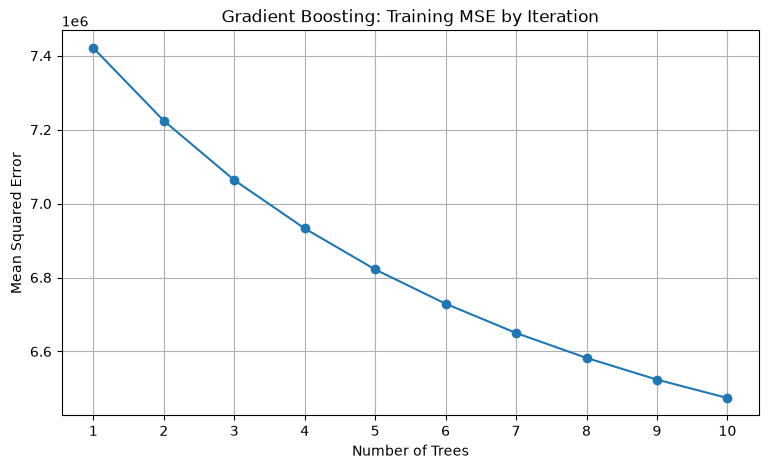

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, n_iterations + 1),
    mse_history,
    marker="o"
)

plt.title("Gradient Boosting: Training MSE by Iteration")
plt.xlabel("Number of Trees")
plt.ylabel("Mean Squared Error")
plt.xticks(range(1, n_iterations + 1))
plt.grid(True)
plt.show()

Initial RMSE: 2768.33
Final RMSE: 2544.42


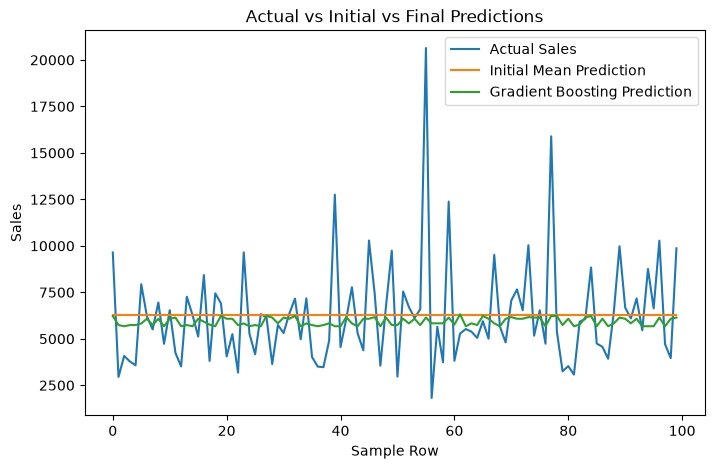

In [14]:
initial_predictions = np.full(
    len(y_scratch),
    y_scratch.mean()
)

print("Initial RMSE:", round(np.sqrt(
    mean_squared_error(y_scratch, initial_predictions)
), 2))

print("Final RMSE:", round(np.sqrt(
    mean_squared_error(y_scratch, scratch_predictions)
), 2))

plt.figure(figsize=(8, 5))

plt.plot(
    y_scratch.iloc[:100].to_numpy(),
    label="Actual Sales"
)

plt.plot(
    initial_predictions[:100],
    label="Initial Mean Prediction"
)

plt.plot(
    scratch_predictions[:100],
    label="Gradient Boosting Prediction"
)

plt.title("Actual vs Initial vs Final Predictions")
plt.xlabel("Sample Row")
plt.ylabel("Sales")
plt.legend()
plt.show()

In [15]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    loss="squared_error"
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully")

Gradient Boosting model trained successfully


In [16]:
gb_predictions = gb_model.predict(X_valid)

gb_rmse = np.sqrt(mean_squared_error(
    y_valid, gb_predictions
))

gb_mae = mean_absolute_error(
    y_valid, gb_predictions
)

gb_r2 = r2_score(
    y_valid, gb_predictions
)

print("Gradient Boosting Results")
print("RMSE:", round(gb_rmse, 2))
print("MAE :", round(gb_mae, 2))
print("R²  :", round(gb_r2, 4))

Gradient Boosting Results
RMSE: 2458.82
MAE : 1757.86
R²  : 0.3644


In [17]:
results = []

# Use a smaller subset for parameter experimentation
X_exp = X_train.iloc[:20000]
y_exp = y_train.iloc[:20000]

X_val_exp = X_valid.iloc[:5000]
y_val_exp = y_valid.iloc[:5000]

for n in [50, 100, 200]:
    for lr in [0.01, 0.1, 0.2]:
        for depth in [3, 5]:

            model = GradientBoostingRegressor(
                n_estimators=n,
                learning_rate=lr,
                max_depth=depth,
                random_state=42,
                loss="squared_error"
            )

            model.fit(X_exp, y_exp)

            pred = model.predict(X_val_exp)

            results.append({
                "n_estimators": n,
                "learning_rate": lr,
                "max_depth": depth,
                "RMSE": np.sqrt(mean_squared_error(y_val_exp, pred)),
                "MAE": mean_absolute_error(y_val_exp, pred),
                "R2": r2_score(y_val_exp, pred)
            })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("RMSE").reset_index(drop=True)
)

print("Best parameter combination:")
display(results_df.loc[[results_df["RMSE"].idxmin()]])

,n_estimators,learning_rate,max_depth,RMSE,MAE,R2
0,200,0.20,5,1430.229842,1046.838423,0.751767
1,100,0.20,5,1664.679557,1225.256901,0.663714
2,200,0.10,5,1664.860048,1221.901567,0.663641
3,200,0.20,3,1828.932860,1346.973221,0.594078
4,50,0.20,5,1901.886116,1399.537654,0.561049
5,100,0.10,5,1988.133985,1455.627486,0.520334
6,100,0.20,3,2062.750527,1510.636283,0.483654
7,200,0.10,3,2092.107040,1526.939689,0.468852
8,50,0.10,5,2175.506537,1588.196301,0.425661
9,50,0.20,3,2250.581026,1642.352185,0.385338


Best parameter combination:


,n_estimators,learning_rate,max_depth,RMSE,MAE,R2
17,200,0.2,5,1430.229842,1046.838423,0.751767


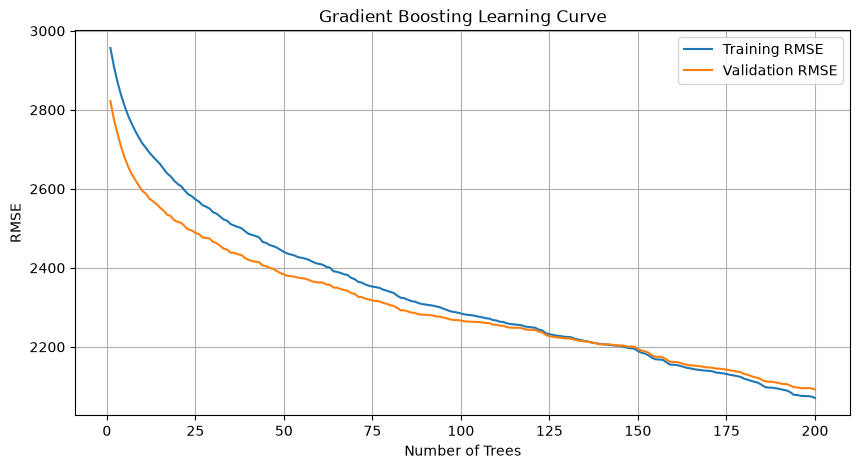

In [18]:
curve_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    loss="squared_error"
)

curve_model.fit(X_exp, y_exp)

train_errors = []
validation_errors = []

for train_pred, val_pred in zip(
    curve_model.staged_predict(X_exp),
    curve_model.staged_predict(X_val_exp)
):
    train_errors.append(
        mean_squared_error(y_exp, train_pred)
    )

    validation_errors.append(
        mean_squared_error(y_val_exp, val_pred)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 201),
    np.sqrt(train_errors),
    label="Training RMSE"
)

plt.plot(
    range(1, 201),
    np.sqrt(validation_errors),
    label="Validation RMSE"
)

plt.title("Gradient Boosting Learning Curve")
plt.xlabel("Number of Trees")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
comparison_models = {
    "lr=0.1, trees=100": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "lr=0.01, trees=500": GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.01,
        max_depth=3,
        random_state=42
    )
}

lr_results = []

for name, model in comparison_models.items():

    model.fit(X_exp, y_exp)

    pred = model.predict(X_val_exp)

    lr_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_val_exp, pred)),
        "MAE": mean_absolute_error(y_val_exp, pred),
        "R2": r2_score(y_val_exp, pred)
    })

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df)

,Model,RMSE,MAE,R2
0,"lr=0.1, trees=100",2266.815286,1644.611722,0.376438
1,"lr=0.01, trees=500",2395.334523,1731.731902,0.303727


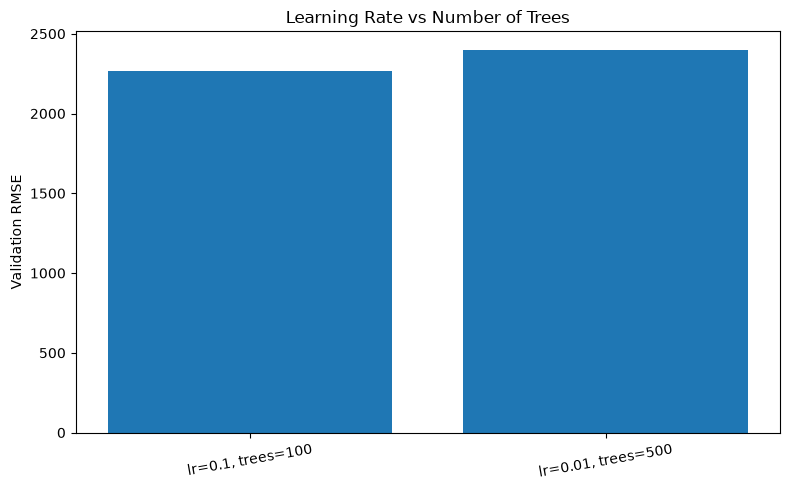

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    lr_results_df["Model"],
    lr_results_df["RMSE"]
)

plt.title("Learning Rate vs Number of Trees")
plt.ylabel("Validation RMSE")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [22]:
models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

comparison_results = []
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_exp, y_exp)

    predictions = model.predict(X_val_exp)

    rmse = np.sqrt(mean_squared_error(
        y_val_exp, predictions
    ))

    mae = mean_absolute_error(
        y_val_exp, predictions
    )

    r2 = r2_score(
        y_val_exp, predictions
    )

    comparison_results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values("RMSE").reset_index(drop=True)
)

Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting


,Model,RMSE,MAE,R2
0,Random Forest,1703.808342,1190.038185,0.647719
1,Gradient Boosting,2266.815286,1644.611722,0.376438
2,Decision Tree,2366.886366,1647.699694,0.320167


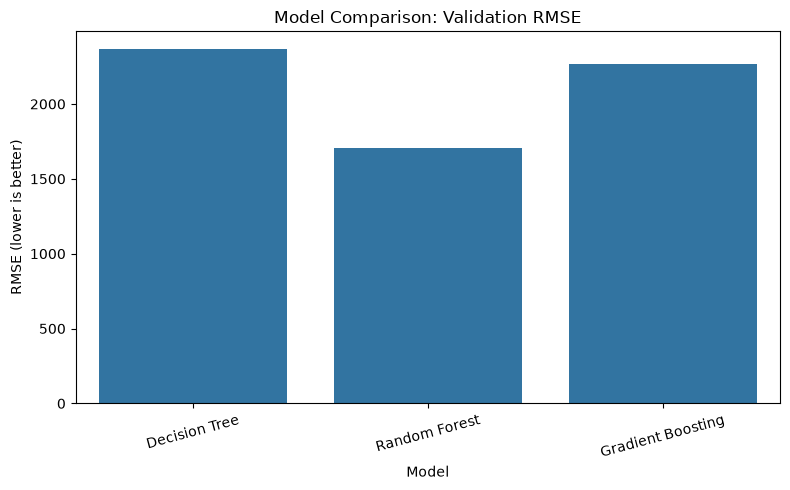

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison: Validation RMSE")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [24]:
importance_data = pd.DataFrame({
    "Feature": features
})

for name, model in trained_models.items():

    importance_data[name] = model.feature_importances_

display(
    importance_data.sort_values(
        "Gradient Boosting",
        ascending=False
    ).reset_index(drop=True)
)

,Feature,Decision Tree,Random Forest,Gradient Boosting
0,Promo,0.206073,0.142835,0.294126
1,CompetitionDistance,0.214328,0.222036,0.178344
2,Store,0.136665,0.161410,0.102732
3,DayOfWeek,0.072459,0.061874,0.082565
4,Day,0.041072,0.049860,0.047139
5,Promo2SinceYear,0.038150,0.030199,0.045403
6,CompetitionOpenSinceYear,0.064868,0.081828,0.043223
7,CompetitionOpenSinceMonth,0.056650,0.073792,0.038353
8,PromoInterval,0.051080,0.026715,0.031408
9,Promo2,0.003518,0.014608,0.029488


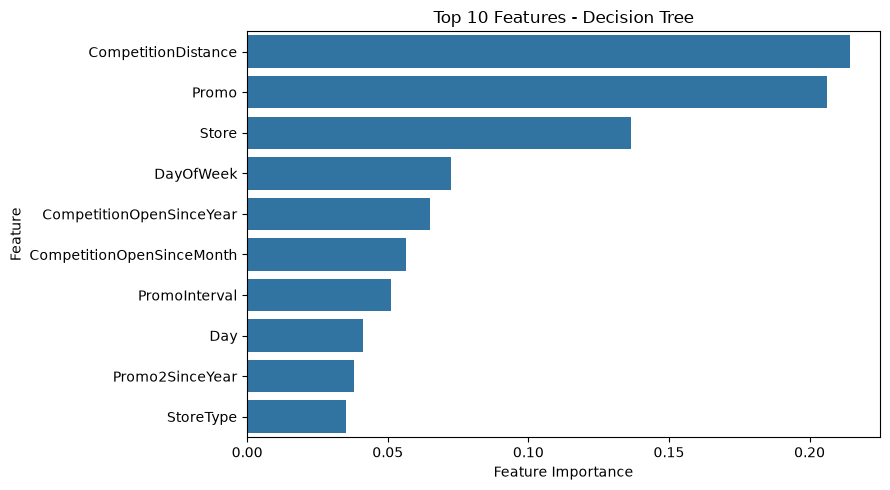

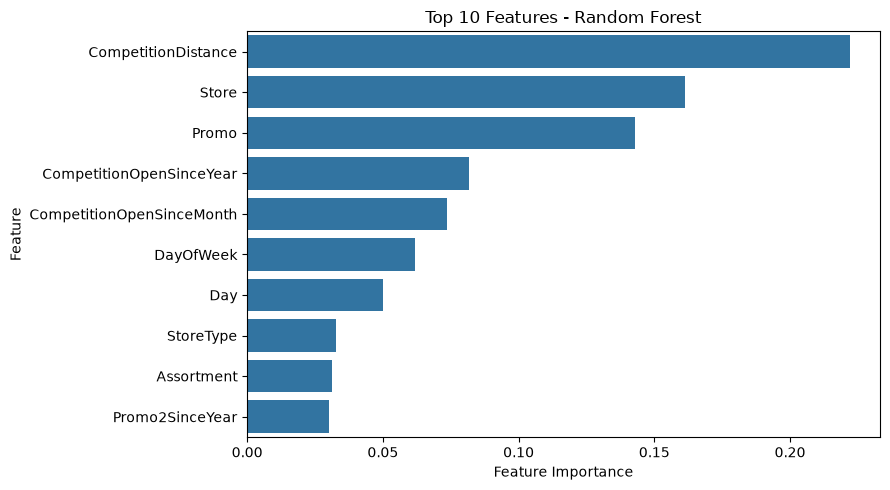

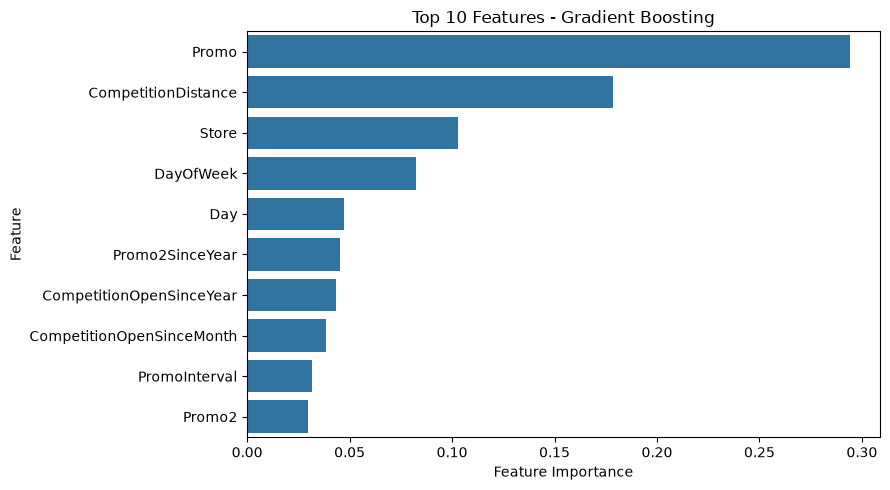

In [25]:
importance_columns = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]

for name in importance_columns:

    top_features = importance_data.nlargest(10, name)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=top_features,
        x=name,
        y="Feature"
    )

    plt.title("Top 10 Features - " + name)
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

In [26]:
importance_ranks = importance_data[["Feature"]].copy()

for name in importance_columns:
    importance_ranks[name + " Rank"] = (
        importance_data[name]
        .rank(ascending=False, method="min")
    )

rank_columns = [name + " Rank" for name in importance_columns]

importance_ranks["Average Rank"] = (
    importance_ranks[rank_columns].mean(axis=1)
)

importance_ranks = importance_ranks.sort_values(
    "Average Rank"
)

display(importance_ranks.head(10))

,Feature,Decision Tree Rank,Random Forest Rank,Gradient Boosting Rank,Average Rank
7,CompetitionDistance,1.0,1.0,2.0,1.333333
2,Promo,2.0,3.0,1.0,2.000000
0,Store,3.0,2.0,3.0,2.666667
1,DayOfWeek,4.0,6.0,4.0,4.666667
9,CompetitionOpenSinceYear,5.0,4.0,7.0,5.333333
8,CompetitionOpenSinceMonth,6.0,5.0,8.0,6.333333
16,Day,8.0,7.0,5.0,6.666667
12,Promo2SinceYear,9.0,10.0,6.0,8.333333
13,PromoInterval,7.0,12.0,9.0,9.333333
5,StoreType,10.0,8.0,12.0,10.000000
